## 2-4. 파이토치 코드 맛보기
- 간단한 분류 및 회귀 모델 개발하는 방법 살펴보기
- 데이터: price, maint, doors, persons, lug_capacity, safety, output(차상태, unacc, acc, good, ver good 중 1)

In [13]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [14]:
cols = ['price', 'maint', 'doors', 'persons', 'lug_capacity', 'safety', 'output']
dataset = pd.read_csv('car_evaluation.csv', names=cols)
display(dataset.head())

,price,maint,doors,persons,lug_capacity,safety,output
0,price,maint,doors,persons,lug_capacity,safety,output
1,vhigh,vhigh,2,2,small,low,unacc
2,vhigh,vhigh,2,2,small,med,unacc
3,vhigh,vhigh,2,2,small,high,unacc
4,vhigh,vhigh,2,2,med,low,unacc


- 다섯 개의 행이 단어와 숫자로 구성됨
- 컴퓨터는 인간의 언어인 단어를 인식할 수 없으므로, 단어를 벡터로 바꾸어 주는 임베딩 처리가 필수적임

<Axes: ylabel='count'>

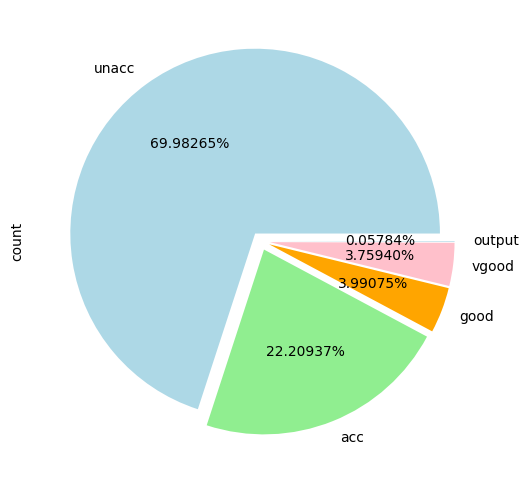

In [18]:
fig_size = plt.rcParams["figure.figsize"]
fig_size[0] = 8
fig_size[1] = 6
plt.rcParams["figure.figsize"] = fig_size
dataset.output.value_counts().plot(kind='pie', autopct='%0.05f%%',
                                   colors=['lightblue','lightgreen','orange','pink'], explode=(0.05, 0.05, 0.05, 0.05))

- 대부분의 자동차는 허용 불가능한 상태이고, 20%만 허용 가능한 수준. 즉, 양호한 상태의 자동차 비율이 매우 낮음


- 단어를 숫자(텐서)로 변환해야 하는 데이터 전처리를 수행해야 함
- 먼저 범주 특성을 갖는 데이터를 범주형 타입으로 변환하고, 범주형 타입을 텐서로 변환해야 함

In [19]:
# 데이터를 범주형 타입으로 변환

categorical_columns = ['price', 'maint', 'doors', 'persons', 'lug_capacity', 'safety']

for category in categorical_columns:
    dataset[category] = dataset[category].astype('category')

price = dataset['price'].cat.codes.values
maint = dataset['maint'].cat.codes.values
doors = dataset['doors'].cat.codes.values
persons = dataset['persons'].cat.codes.values
lug_capacity = dataset['lug_capacity'].cat.codes.values
safety = dataset['safety'].cat.codes.values

categorical_data = np.stack([price, maint, doors, persons, lug_capacity, safety], 1)
categorical_data[:10]


array([[3, 2, 4, 3, 1, 3],
       [4, 4, 0, 0, 3, 1],
       [4, 4, 0, 0, 3, 2],
       [4, 4, 0, 0, 3, 0],
       [4, 4, 0, 0, 2, 1],
       [4, 4, 0, 0, 2, 2],
       [4, 4, 0, 0, 2, 0],
       [4, 4, 0, 0, 0, 1],
       [4, 4, 0, 0, 0, 2],
       [4, 4, 0, 0, 0, 0]], dtype=int8)

- (1) 범주형 데이터를 텐서로 변환하기 위해서 '범주형 데이터 -> dataset(category) -> 넘파이 배열 -> 텐서'와 같은 절차가 필요함
- 즉, 파이토치로 모델을 학습시키기 위해서는 텐서 형태로 변환해야 하는데, 넘파이 배열을 통해 텐서를 생성할 수 있음
- 범주형 데이터(단어)를 숫자(넘파이 배열)로 변환하기 위해서는 cat.codes를 사용해야 함
- (2) np.stack은 두 개 이상의 넘파이 객체를 합칠 때 사용

In [20]:
# 배열을 텐서로 변환
categorical_data = torch.tensor(categorical_data, dtype=torch.int64)
categorical_data[:10]

tensor([[3, 2, 4, 3, 1, 3],
        [4, 4, 0, 0, 3, 1],
        [4, 4, 0, 0, 3, 2],
        [4, 4, 0, 0, 3, 0],
        [4, 4, 0, 0, 2, 1],
        [4, 4, 0, 0, 2, 2],
        [4, 4, 0, 0, 2, 0],
        [4, 4, 0, 0, 0, 1],
        [4, 4, 0, 0, 0, 2],
        [4, 4, 0, 0, 0, 0]])

In [21]:
# 레이블로 사용할 칼럼을 텐서로 변환
outputs = pd.get_dummies(dataset.output)
outputs = outputs.values
outputs = torch.tensor(outputs).flatten()  # 1차원 텐서로 변환

print(categorical_data.shape)
print(outputs.shape)

torch.Size([1729, 6])
torch.Size([8645])


- (1) get_dummies는 가변수(Dummy variable)을 만들어주는 함수. 가변수로 만든다는 것은 문자를 숫자 0, 1롤 바꾸어준다는 의미

In [22]:
# dummy variable 변환 예시 #
import pandas as pd
import numpy as np

data = {
    'gender' : ['male', 'female', 'male'],
    'weight' : [72, 55, 68],
    'nation' : ['Japan', 'Korea', 'Australia']
}

df = pd.DataFrame(data)
df

,gender,weight,nation
0,male,72,Japan
1,female,55,Korea
2,male,68,Australia


In [23]:
pd.get_dummies(df)

,weight,gender_female,gender_male,nation_Australia,nation_Japan,nation_Korea
0,72,False,True,False,True,False
1,55,True,False,False,False,True
2,68,False,True,True,False,False


- 워드 임베딩은 유사한 단어끼리 유사하게 인코딩되도록 표현하는 방법. 또한, 높은 차원의 임베딩일수록 단어 간의 세부적인 관계를 잘 파악할 수 있으므로, 단일 숫자로 변환된 넘파이 배열을 N차원으로 변경하여 사용
- 배열을 N차원으로 변환하기 위해 먼저 모든 범주형 칼럼에 대한 임베딩 크기(벡터 차원)를 정의함. 임베딩 크기에 대한 정확한 규칙은 없지만, 칼럼의 고유 값 수를 2로 나누는 것을 많이 사용함

In [24]:
# 범주형 칼럼을 N차원으로 변환
categorical_column_sizes = [len(dataset[column].cat.categories) for column in categorical_columns]
categorical_embedding_sizes = [(col_size, min(50, (col_size+1)//2)) for col_size in categorical_column_sizes]

print(categorical_embedding_sizes)

[(5, 3), (5, 3), (5, 3), (4, 2), (4, 2), (4, 2)]


In [25]:
# 데이터셋 분리
total_records = 1728
test_records = int(total_records * .2)

categorical_train_data = categorical_data[:total_records-test_records]
categorical_test_data = categorical_data[total_records-test_records:total_records]
train_outputs = outputs[:total_records-test_records]
test_outputs = outputs[total_records-test_records:total_records]

In [26]:
# 데이터셋 분리 확인
print(len(categorical_train_data))
print(len(train_outputs))
print(len(categorical_test_data))
print(len(test_outputs))

1383
1383
345
345


In [27]:
# 모델의 네트워크 생성
class Model(nn.Module):
  def __init__(self, embedding_size, output_size, layers, p=0.4):
    super().__init__()
    self.all_embeddings = nn.ModuleList([nn.Embedding(ni, nf) for ni,
                                         nf in embedding_size])
    self.embedding_dropout = nn.Dropout(p)

    all_layers = []
    num_categorical_cols = sum((nf for ni, nf in embedding_size))
    input_size = num_categorical_cols

    for i in layers:
      all_layers.append(nn.Linear(input_size, i))
      all_layers.append(nn.ReLU(inplace=True))
      all_layers.append(nn.BatchNorm1d(i))
      all_layers.append(nn.Dropout(p))
      input_size = i

    all_layers.append(nn.Linear(layers[-1], output_size))
    self.layers = nn.Sequential(*all_layers)

  def forward(self, x_categorical):
    embeddings = []
    for i, e in enumerate(self.all_embeddings):
      embeddings.append(e(x_categorical[:, i]))

    x = torch.cat(embeddings, 1)
    x = self.embedding_dropout(x)
    x = self.layers(x)

    return x

- (1) class 형태로 구현되는 모델은 nn.Module을 상속 받음
- (2) __init__()은 모델에서 사용될 파라미터와 신경망을 초기화하기 위한 용도로 사용하며, 객체가 생성될 때 자동 호출
- (3) super().__init__()은 부모 클래스(nn.Module)에 접근할 때 사용
- (4) 모델의 네트워크 계층을 구축하기 위해 for 문을 이용해 각 계층을 all_layers 목록에 추가
- (5) forward() 함수는 학습 데이터를 입력받아서 연산을 진행. forward() 함수는 모델 객체를 데이터와 함께 호출하면 자동으로 실행됨

In [28]:
# Model 클래스의 객체 생성
model = Model(categorical_embedding_sizes, 4, [200, 100, 50], p=0.4)
print(model)

Model(
  (all_embeddings): ModuleList(
    (0-2): 3 x Embedding(5, 3)
    (3-5): 3 x Embedding(4, 2)
  )
  (embedding_dropout): Dropout(p=0.4, inplace=False)
  (layers): Sequential(
    (0): Linear(in_features=15, out_features=200, bias=True)
    (1): ReLU(inplace=True)
    (2): BatchNorm1d(200, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=200, out_features=100, bias=True)
    (5): ReLU(inplace=True)
    (6): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): Dropout(p=0.4, inplace=False)
    (8): Linear(in_features=100, out_features=50, bias=True)
    (9): ReLU(inplace=True)
    (10): BatchNorm1d(50, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): Dropout(p=0.4, inplace=False)
    (12): Linear(in_features=50, out_features=4, bias=True)
  )
)


In [29]:
# 모델의 파라미터 정의
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [30]:
# GPU/CPU 사용 지정
if torch.cuda.is_available():
  device = torch.device('cuda')

else:
  device = torch.device('cpu')

In [31]:
# 모델 학습
epochs = 500
aggregated_losses = []

train_outputs = train_outputs.to(device=device, dtype=torch.int64)

for i in range(epochs):
    i += 1

    y_pred = model(categorical_train_data).to(device)
    single_loss = loss_function(y_pred, train_outputs)
    aggregated_losses.append(single_loss)

    if i % 25 == 1:
        print(f'epoch: {i:3} loss: {single_loss.item():10.8f}')

    optimizer.zero_grad()
    single_loss.backward()
    optimizer.step()

print(f'epoch: {i:3} loss: {single_loss.item():10.10f}')

epoch:   1 loss: 1.63963962
epoch:  26 loss: 1.42546284
epoch:  51 loss: 1.33868718
epoch:  76 loss: 1.21444643
epoch: 101 loss: 1.05280030
epoch: 126 loss: 0.93489069
epoch: 151 loss: 0.78571892
epoch: 176 loss: 0.68778843
epoch: 201 loss: 0.66134065
epoch: 226 loss: 0.60920066
epoch: 251 loss: 0.57912737
epoch: 276 loss: 0.55508178
epoch: 301 loss: 0.54919934
epoch: 326 loss: 0.53848082
epoch: 351 loss: 0.54671186
epoch: 376 loss: 0.52876353
epoch: 401 loss: 0.52991539
epoch: 426 loss: 0.52066886
epoch: 451 loss: 0.51837689
epoch: 476 loss: 0.51593632
epoch: 500 loss: 0.5192041993


In [32]:
# 테스트 데이터셋으로 모델 예측
test_outputs = test_outputs.to(device=device, dtype=torch.int64)
with torch.no_grad():
  y_val = model(categorical_test_data)
  loss = loss_function(y_val, test_outputs)
print(f'Loss: {loss:.8f}')

Loss: 0.51128018


In [33]:
# 모델 예측 확인
print(y_val[:5])

tensor([[  4.0153,   2.1688,  -5.0790,  -5.0062],
        [  3.0775,   1.8100,  -3.3470,  -3.4680],
        [  2.3447,   1.2788,  -3.0012,  -2.8601],
        [  3.1603,   1.5543,  -4.8822,  -4.4941],
        [ 12.2775,   8.6950, -12.5560, -13.4441]])


In [34]:
# 가장 큰 값을 갖는 인덱스 확인
y_val = np.argmax(y_val, axis=1)
print(y_val[:5])

tensor([0, 0, 0, 0, 0])


In [35]:
# 테스트 데이터셋을 이용한 정확도 화긴
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
print(confusion_matrix(test_outputs, y_val))
print(classification_report(test_outputs, y_val))
print(accuracy_score(test_outputs, y_val))

[[275   1]
 [ 69   0]]
              precision    recall  f1-score   support

           0       0.80      1.00      0.89       276
           1       0.00      0.00      0.00        69

    accuracy                           0.80       345
   macro avg       0.40      0.50      0.44       345
weighted avg       0.64      0.80      0.71       345

0.7971014492753623


#### 딥러닝 분류 모델의 성능 평가 지표
- 성능 평가 지표로 정확도(accuracy), 재현율(recall), 정밀도(precision), F1-스코어(F1-score)
- True Positive: 모델(분류기)이 '1'이라고 예측했는데 실제 값도 '1'인 경우
- True Negative: 모델(분류기)이 '0'이라고 예측했는데 실제 값도 '0'인 경우
- False Positive: 모델(분류기)이 '1'이라고 예측했는데 실제 값은 '0'인 경우로, Type1 오류라고도 함
- False Negative: 모델(분류기)이 '0'이라고 예측했는데 실제 값은 '1'인 경우로，Type2 오류라고도 함

- **정확도**: 전체 예측 건수에서 정답을 맞힌 건수의 비율. 이때 맞힌 정답이 긍정(positive)이든 부정(negative)이든 상관없음
- **재현율**: 실제로 정답이 1이라고 할 때 모델(분류기)도 1로 예측한 비율. 따라서 처음부터 데이터가 1일 획률이 적을 때 사용하면 좋음
- **정밀도**: 모델(분류기)이 1이라고 예측한 것 중에서 실제로 정답이 1인 비율
- **F1 스코어**: 일반적으로 정밀도와 재현율은 트레이드오프(trade-off) 관계. 정밀도가 높으면 재현율이 낮고 재현율이 높으면 정밀도가 낮음. 이러한 트레이드오프 문제를 해결하려고 정밀도와 재현율의 조화 평균(harmonic mean)을 이용한 것이 F1-스코어 평가
